 A. To use PCA Algorithm for dimensionality reduction. You have a dataset that includes measurements for different variables on wine (alcohol, ash, magnesium, and so on). Apply PCA algorithm & transform this data so that most variations in the measurements of the variables are captured by a small number of principal components so that it is easier to distinguish between red and white wine by inspecting these principal components. Dataset Link: https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv

In [7]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [8]:
# Load the wine dataset
# Keep Wine.csv in the same folder as this notebook
df = pd.read_csv("Wine.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (178, 14)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [9]:
# Separate input features and class labels
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

print("Number of features:", X.shape[1])
print("Wine classes:", sorted(y.unique()))

Number of features: 13
Wine classes: [1, 2, 3]


In [10]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [11]:
# Reduce the features to two principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Wine_Class"] = y.values

# Show how much variance each component captures
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance captured:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")
pca_df.head()

Explained variance ratio: [0.36198848 0.1920749 ]
Total variance captured: 55.41 %


,PC1,PC2,Wine_Class
0,3.316751,1.443463,1
1,2.209465,-0.333393,1
2,2.516740,1.031151,1
3,3.757066,2.756372,1
4,1.008908,0.869831,1


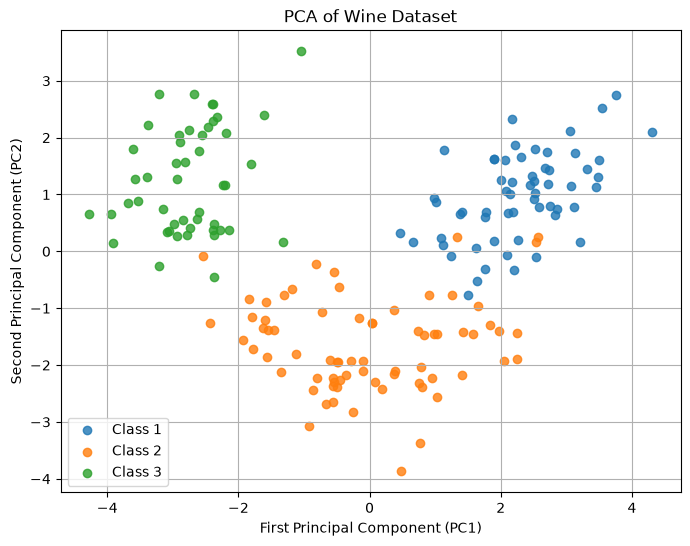

In [12]:
# Plot the two principal components by wine class
plt.figure(figsize=(8, 6))

for wine_class in sorted(pca_df["Wine_Class"].unique()):
    data = pca_df[pca_df["Wine_Class"] == wine_class]
    plt.scatter(data["PC1"], data["PC2"], label=f"Class {wine_class}", alpha=0.8)

plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("PCA of Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()